In [2]:
!pip install -q GEOparse

In [3]:

import GEOparse

gse = GEOparse.get_GEO(geo="GSE70394", destdir="./data")

print("Samples:", len(gse.gsms))
print("Platforms:", list(gse.gpls.keys()))
print("Title:", gse.metadata["title"][0])

26-Oct-2026 06:56:18 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE70nnn/GSE70394/soft/GSE70394_family.soft.gz to ./data/GSE70394_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE70nnn/GSE70394/soft/GSE70394_family.soft.gz to ./data/GSE70394_family.soft.gz
100%|██████████| 8.24M/8.24M [00:01<00:00, 4.63MB/s]
26-Oct-2026 06:56:22 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
26-Oct-2026 06:56:22 DEBUG downloader - Moving /tmp/tmp1uj89ks5 to /content/data/GSE70394_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp1uj89ks5 to /content/data/GSE70394_family.soft.gz
26-Oct-2026 06:56:22 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE70nnn/GSE70394/soft/GSE70394_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE70nnn/GSE70394/soft/GSE70394_family.soft.gz
26-Oct-2026 06:56:22 INFO GEOparse - Parsing ./data/GSE70394_family.soft.gz

Samples: 6
Platforms: ['GPL6480']
Title: Gene expression profiling of gastric cells infected by Helicobacter pylori


In [4]:

import pandas as pd
import numpy as np

frames = {}
for name, gsm in gse.gsms.items():
    if len(gsm.table) > 0:
        frames[name] = gsm.table.set_index("ID_REF")["VALUE"]

exprs = pd.concat(frames, axis=1)
exprs = exprs.apply(pd.to_numeric, errors="coerce")

print("Shape (probes x samples):", exprs.shape)
print("Value range:", exprs.min().min(), "to", exprs.max().max())

if exprs.max().max() > 50:
    exprs = np.log2(exprs + 1)
    print("Converted to log2 scale.")
else:
    print("Already on log scale -- no conversion needed.")

Shape (probes x samples): (30102, 6)
Value range: 1.803447485 to 16.9107666
Already on log scale -- no conversion needed.


In [5]:

def parse_characteristics(gsm):
    info = {}
    for entry in gsm.metadata.get("characteristics_ch1", []):
        if ":" in entry:
            key, value = entry.split(":", 1)
            info[key.strip()] = value.strip()
    return info

pheno = pd.DataFrame({name: parse_characteristics(gsm)
                      for name, gsm in gse.gsms.items()}).T
print(pheno)

infection_col = [c for c in pheno.columns if "infect" in c.lower()][0]
groups = pheno[infection_col].unique()
print("Groups found:", list(groups))

def pick_infected(labels):
    for lab in labels:
        low = lab.lower()
        if "infect" in low and "uninfect" not in low and "non" not in low and "control" not in low:
            return lab
    return sorted(labels)[0]

infected_label = pick_infected(groups)
control_label = [g for g in groups if g != infected_label][0]
print("Infected group:", infected_label, "| Control group:", control_label)

                                                cell line  \
GSM1726497  Human gastric carcinoma-derived cell line AGS   
GSM1726498  Human gastric carcinoma-derived cell line AGS   
GSM1726499  Human gastric carcinoma-derived cell line AGS   
GSM1726500  Human gastric carcinoma-derived cell line AGS   
GSM1726501  Human gastric carcinoma-derived cell line AGS   
GSM1726502  Human gastric carcinoma-derived cell line AGS   

                         infection  
GSM1726497              uninfected  
GSM1726498  H. pylori strain 60190  
GSM1726499              uninfected  
GSM1726500  H. pylori strain 60190  
GSM1726501              uninfected  
GSM1726502  H. pylori strain 60190  
Groups found: ['uninfected', 'H. pylori strain 60190']
Infected group: H. pylori strain 60190 | Control group: uninfected


In [6]:

from scipy import stats
from statsmodels.stats.multitest import multipletests

inf_idx = pheno[pheno[infection_col] == infected_label].index
ctl_idx = pheno[pheno[infection_col] == control_label].index
inf = exprs[[s for s in exprs.columns if s in inf_idx]]
ctl = exprs[[s for s in exprs.columns if s in ctl_idx]]
print("Infected samples:", inf.shape[1], "| Control samples:", ctl.shape[1])

t_vals, p_vals = stats.ttest_ind(inf.values, ctl.values, axis=1,
                                 equal_var=False, nan_policy="omit")

log2fc = np.nanmean(inf.values, axis=1) - np.nanmean(ctl.values, axis=1)

_, padj, _, _ = multipletests(p_vals, method="fdr_bh")

results = pd.DataFrame({
    "probe_id": exprs.index,
    "log2FC": log2fc,
    "p_value": p_vals,
    "padj": padj,
}).set_index("probe_id").sort_values("padj")

results["significant"] = (results["padj"] < 0.05) & (results["log2FC"].abs() > 1)
print("Significant genes:", int(results["significant"].sum()), "of", len(results))
print(results.head(10))
results.to_csv("week1_deg_results.csv")
print("Saved: week1_deg_results.csv")

Infected samples: 3 | Control samples: 3


/usr/local/lib/python3.13/dist-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


Significant genes: 0 of 30102
                   log2FC   p_value  padj  significant
probe_id                                              
GE_BrightCorner  0.180796  0.622925   NaN        False
A_24_P66027      1.353074  0.028067   NaN        False
A_32_P77178     -0.259778  0.501870   NaN        False
A_23_P212522    -0.991360  0.106583   NaN        False
A_24_P934473    -0.449416  0.319938   NaN        False
A_24_P9671      -0.188357  0.321920   NaN        False
A_32_P29551      1.052598  0.176014   NaN        False
A_24_P801451    -0.510596  0.169861   NaN        False
A_32_P30710     -0.002837  0.989910   NaN        False
A_32_P89523      0.257810  0.608665   NaN        False
Saved: week1_deg_results.csv


/tmp/ipykernel_2192/3499665964.py:13: RuntimeWarning: Mean of empty slice
  log2fc = np.nanmean(inf.values, axis=1) - np.nanmean(ctl.values, axis=1)


In [7]:

from scipy import stats
from statsmodels.stats.multitest import multipletests

inf_idx = pheno[pheno[infection_col] == infected_label].index
ctl_idx = pheno[pheno[infection_col] == control_label].index
inf = exprs[[s for s in exprs.columns if s in inf_idx]]
ctl = exprs[[s for s in exprs.columns if s in ctl_idx]]
print("Infected samples:", inf.shape[1], "| Control samples:", ctl.shape[1])

# THE FIX, part 1: keep only probes measured in at least 2 of 3 samples per group
keep = (inf.notna().sum(axis=1) >= 2) & (ctl.notna().sum(axis=1) >= 2)
inf, ctl = inf[keep], ctl[keep]
print("Probes kept after missing-value filter:", len(inf), "of", len(exprs))

t_vals, p_vals = stats.ttest_ind(inf.values, ctl.values, axis=1,
                                 equal_var=False, nan_policy="omit")

log2fc = np.nanmean(inf.values, axis=1) - np.nanmean(ctl.values, axis=1)

# THE FIX, part 2: drop any probe whose p-value still came out NaN
ok = ~np.isnan(p_vals)
probe_ids = inf.index[ok]
t_vals, p_vals, log2fc = t_vals[ok], p_vals[ok], log2fc[ok]

_, padj, _, _ = multipletests(p_vals, method="fdr_bh")

results = pd.DataFrame({
    "probe_id": probe_ids,
    "log2FC": log2fc,
    "p_value": p_vals,
    "padj": padj,
}).set_index("probe_id").sort_values("padj")

results["significant"] = (results["padj"] < 0.05) & (results["log2FC"].abs() > 1)
print("Significant genes:", int(results["significant"].sum()), "of", len(results))
print(results.head(10))
results.to_csv("week1_deg_results.csv")
print("Saved: week1_deg_results.csv")

Infected samples: 3 | Control samples: 3
Probes kept after missing-value filter: 29009 of 30102
Significant genes: 0 of 29009
                log2FC   p_value      padj  significant
probe_id                                               
A_32_P86705   0.687458  0.000025  0.278040        False
A_32_P215179 -0.587100  0.000022  0.278040        False
A_24_P208825  2.282052  0.000029  0.278040        False
A_23_P404965 -1.381977  0.000057  0.409795        False
A_23_P21640  -1.000354  0.000146  0.535531        False
A_24_P358084 -0.550874  0.000185  0.535531        False
A_23_P326160  1.129299  0.000156  0.535531        False
A_23_P38505   0.695732  0.000148  0.535531        False
A_23_P406227  1.230417  0.000174  0.535531        False
A_23_P21155   0.724748  0.000113  0.535531        False
Saved: week1_deg_results.csv


Saved: week1_volcano.png


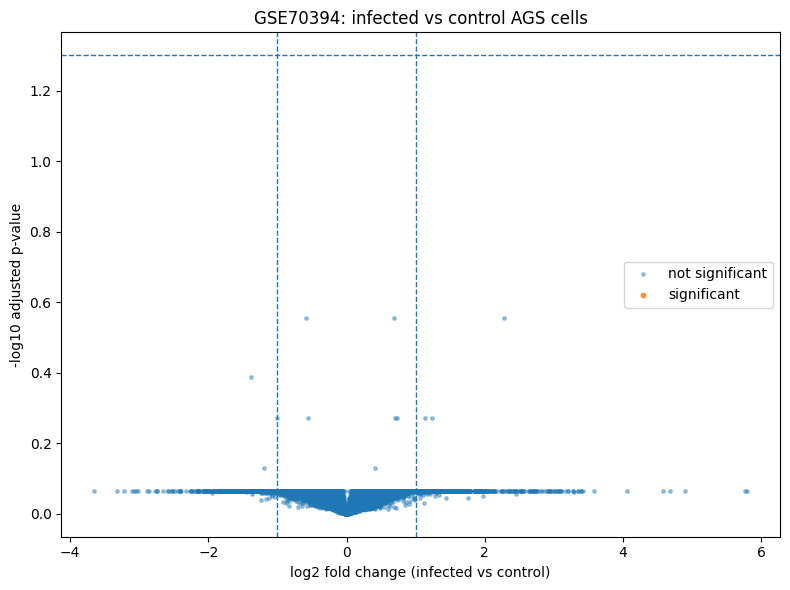

In [8]:
import matplotlib.pyplot as plt

# Volcano plot: x = HOW MUCH it changed, y = HOW SURE we are.
# Top corners = the interesting genes: big change + high confidence.
plot_df = results.copy()
plot_df["neg_log10_padj"] = -np.log10(plot_df["padj"].replace(0, 1e-300))

plt.figure(figsize=(8, 6))
sig = plot_df["significant"]
plt.scatter(plot_df.loc[~sig, "log2FC"], plot_df.loc[~sig, "neg_log10_padj"],
            s=6, alpha=0.4, label="not significant")
plt.scatter(plot_df.loc[sig, "log2FC"], plot_df.loc[sig, "neg_log10_padj"],
            s=10, alpha=0.8, label="significant")
plt.axhline(-np.log10(0.05), linestyle="--", linewidth=1)   # padj = 0.05 line
plt.axvline(1, linestyle="--", linewidth=1)                  # |log2FC| = 1 lines
plt.axvline(-1, linestyle="--", linewidth=1)
plt.xlabel("log2 fold change (infected vs control)")
plt.ylabel("-log10 adjusted p-value")
plt.title("GSE70394: infected vs control AGS cells")
plt.legend()
plt.tight_layout()
plt.savefig("week1_volcano.png", dpi=150)
print("Saved: week1_volcano.png")


ValueError: The condensed distance matrix must contain only finite values.

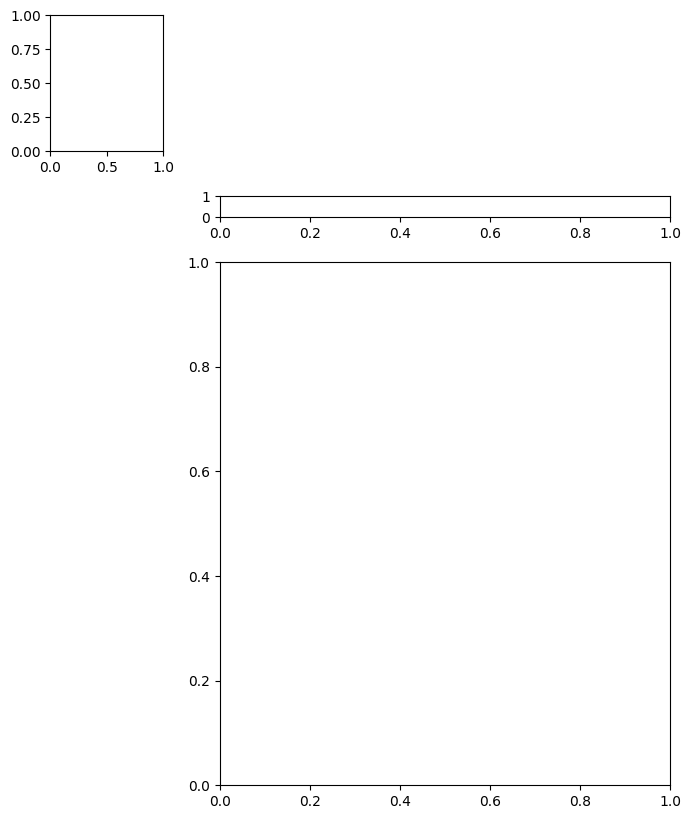

In [9]:
import seaborn as sns

# Heatmap of the top 25 genes: rows = genes, columns = samples.
# z_score=0 rescales each gene's row, so PATTERNS show instead of raw brightness.
top25 = results.head(25).index
heat_data = exprs.loc[top25]

sample_groups = [infected_label if s in inf.columns else control_label
                 for s in heat_data.columns]
lut = {infected_label: "#d73027", control_label: "#4575b4"}   # red vs blue bar
col_colors = pd.Series(sample_groups, index=heat_data.columns).map(lut)

g = sns.clustermap(heat_data, z_score=0, cmap="vlag", center=0,
                   col_colors=col_colors, figsize=(8, 10),
                   yticklabels=False, xticklabels=False)
g.fig.suptitle("Top 25 differentially expressed genes", y=1.02)
g.savefig("week1_heatmap.png", dpi=150)
print("Saved: week1_heatmap.png")


NaN holes before fix: 1
NaN holes after fix: 0
Saved: week1_heatmap.png


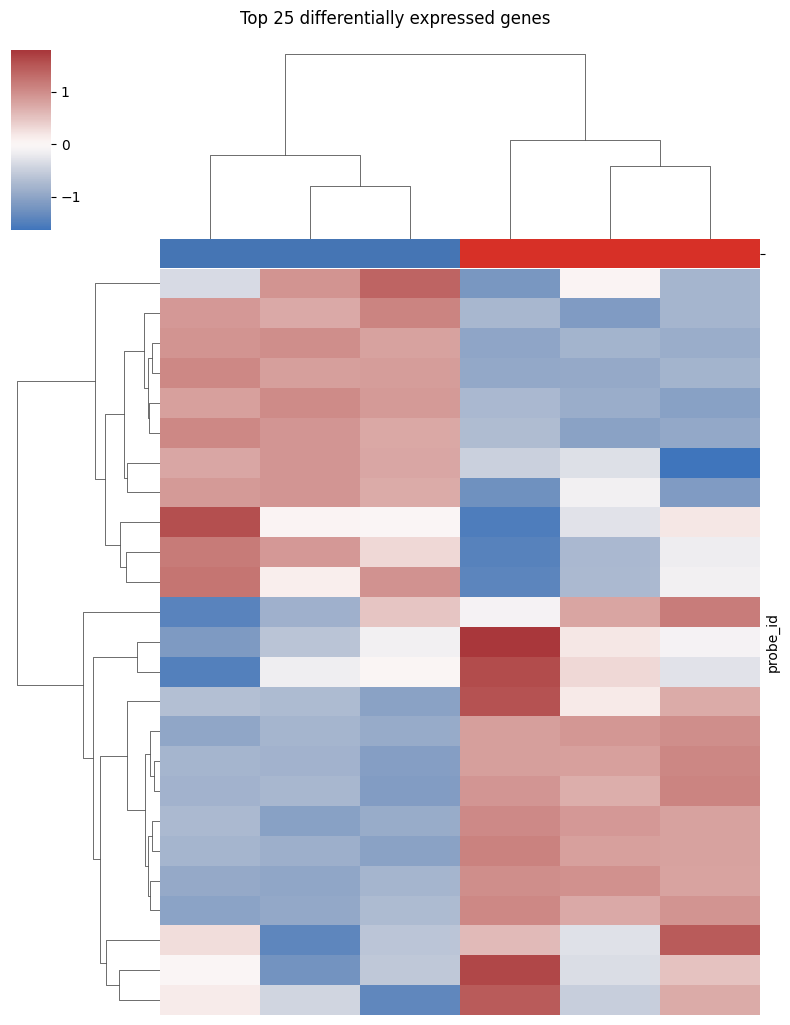

In [10]:
import seaborn as sns

# Heatmap of the top 25 genes: rows = genes, columns = samples.
# z_score=0 rescales each gene's row, so PATTERNS show instead of raw brightness.
top25 = results.head(25).index
heat_data = exprs.loc[top25]

# FIX: patch the holes before drawing.
# Fill each hole with that gene's own average across samples.
print("NaN holes before fix:", int(heat_data.isna().sum().sum()))
heat_data = heat_data.apply(lambda row: row.fillna(row.mean()), axis=1)
print("NaN holes after fix:", int(heat_data.isna().sum().sum()))

sample_groups = [infected_label if s in inf.columns else control_label
                 for s in heat_data.columns]
lut = {infected_label: "#d73027", control_label: "#4575b4"}   # red vs blue bar
col_colors = pd.Series(sample_groups, index=heat_data.columns).map(lut)

g = sns.clustermap(heat_data, z_score=0, cmap="vlag", center=0,
                   col_colors=col_colors, figsize=(8, 10),
                   yticklabels=False, xticklabels=False)
g.fig.suptitle("Top 25 differentially expressed genes", y=1.02)
g.savefig("week1_heatmap.png", dpi=150)
print("Saved: week1_heatmap.png")


In [11]:
# Peek first: what chip is this, and what columns does its annotation table have?
gpl_name = list(gse.gpls.keys())[0]
gpl_table = gse.gpls[gpl_name].table
print("Platform:", gpl_name)
print("Columns:", list(gpl_table.columns)[:20])


Platform: GPL6480
Columns: ['ID', 'SPOT_ID', 'CONTROL_TYPE', 'REFSEQ', 'GB_ACC', 'GENE', 'GENE_SYMBOL', 'GENE_NAME', 'UNIGENE_ID', 'ENSEMBL_ID', 'TIGR_ID', 'ACCESSION_STRING', 'CHROMOSOMAL_LOCATION', 'CYTOBAND', 'DESCRIPTION', 'GO_ID', 'SEQUENCE']


In [12]:
# Turn probe IDs into gene names, using YOUR chip's columns.
# "ID" is the probe, "GENE_SYMBOL" is the gene name.
# drop_duplicates first, so each probe maps to exactly one name.
annot = gpl_table.drop_duplicates("ID").set_index("ID")["GENE_SYMBOL"]
results["gene_symbol"] = results.index.map(annot)

# 1) Did the mapping work? Top 10 rows, now with names.
print(results[["gene_symbol", "log2FC", "padj"]].head(10))

# 2) The heatmap's 25 genes, now with names.
print(results[["gene_symbol", "log2FC", "padj"]].head(25))

# 3) The "does it rhyme with R" check: where did your R genes land?
# Here you check DIRECTION (log2FC sign), not significance -- BH already
# refused to certify anything, so a matching direction is the win.
for gene in ["IL24", "BIRC3", "MUC4", "FGA", "FGG"]:
    hit = results[results["gene_symbol"] == gene].sort_values("padj")
    if len(hit) > 0:
        row = hit.iloc[0]
        print(gene, "-> log2FC:", round(row["log2FC"], 2),
              "| padj:", round(row["padj"], 3))
    else:
        print(gene, "-> not found under this symbol")

# Save the named table for the repo.
results.to_csv("week1_deg_results_named.csv")
print("Saved: week1_deg_results_named.csv")


             gene_symbol    log2FC      padj
probe_id                                    
A_32_P86705          NaN  0.687458  0.278040
A_32_P215179        NPIP -0.587100  0.278040
A_24_P208825        MUC4  2.282052  0.278040
A_23_P404965        GNL1 -1.381977  0.409795
A_23_P21640         CHD3 -1.000354  0.535531
A_24_P358084         NaN -0.550874  0.535531
A_23_P326160     ZC3H12A  1.129299  0.535531
A_23_P38505       CXCL16  0.695732  0.535531
A_23_P406227    MGC23284  1.230417  0.535531
A_23_P21155         EDC3  0.724748  0.535531
             gene_symbol    log2FC      padj
probe_id                                    
A_32_P86705          NaN  0.687458  0.278040
A_32_P215179        NPIP -0.587100  0.278040
A_24_P208825        MUC4  2.282052  0.278040
A_23_P404965        GNL1 -1.381977  0.409795
A_23_P21640         CHD3 -1.000354  0.535531
A_24_P358084         NaN -0.550874  0.535531
A_23_P326160     ZC3H12A  1.129299  0.535531
A_23_P38505       CXCL16  0.695732  0.535531
A_23_P4062